In [1]:
import os
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # 0 (default) = all messages, 1 = INFO messages, 2 = INFO and WARNING messages, 3 = only ERROR messages
logging.getLogger('tensorflow').setLevel(logging.ERROR)  # Suppress TensorFlow INFO and WARNING messages
import wfdb
import tensorflow as tf
from scipy.signal import butter, filtfilt, iirnotch
from matplotlib import pyplot as plt

2024-02-25 15:20:02.320609: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-02-25 15:20:02.320658: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-02-25 15:20:02.321494: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
def force_data(path):
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    force_signal = wfdb.rdsamp(path[:-4])[0]
    force_signal = force_signal[5:]
    ######################################################
    # Filter the high frequencies
    ######################################################
    force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
    return force_signal

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

In [3]:
emg_path = "../data/1dof_dataset/subject01_session1/1dof_preprocess_finger1_sample1.hea"
force_path = "../data/1dof_dataset/subject01_session1/1dof_force_finger1_sample1.hea"

In [4]:
emg_signal = wfdb.rdsamp(emg_path[:-4])[0]
emg_signal = tf.cast(emg_signal, dtype=tf.float32)
force_signal = force_data(force_path)

In [5]:
print(f"Shape of emg signal: {emg_signal.shape}")
print(f"Shape of force signal: {force_signal.shape}")

Shape of emg signal: (51200, 256)
Shape of force signal: (2495, 5)


In [6]:
import numpy as np
from scipy import interpolate

def interpolate_force_to_emg(force_signal, emg_signal):
    """
    Interpola um sinal de força para ter o mesmo formato que um sinal de EMG.

    Parâmetros:
        - force_signal: array numpy com o sinal de força de entrada, com shape (n_samples_force, n_channels)
        - emg_signal: array numpy com o sinal de EMG de referência, com shape (n_samples_emg, n_channels)
    
    Retorna:
        - interpolated_signals: array numpy com os sinais de força interpolados, com shape (n_samples_emg, n_channels)
    
    Exemplo de uso:
        - interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)
    """
    interpolated_signals = np.zeros_like(emg_signal)  # Array para armazenar os sinais interpolados

    for i in range(force_signal.shape[1]):  # Para cada canal
        x = np.arange(0, force_signal.shape[0])  # Índices originais do sinal de força
        y = force_signal[:, i]  # Valor do sinal de força
        f = interpolate.interp1d(x, y, kind='cubic')  # Função de interpolação cúbica
        x_new = np.linspace(0, force_signal.shape[0] - 1, emg_signal.shape[0])  # Novos índices para o sinal de EMG
        interpolated_signals[:, i] = f(x_new)  # Interpolar o sinal de força para o sinal de EMG

    return interpolated_signals

In [7]:
interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)

print(f"Shape of force signal: {interpolated_force.shape}")

Shape of force signal: (51200, 256)


In [8]:
def plot_signals(original_signal, interpolated_signal, signal_names):
    num_channels = original_signal.shape[1]
    fig, axs = plt.subplots(num_channels, 2, figsize=(14, 8))

    for i in range(num_channels):
        axs[i, 0].plot(original_signal[:, i], label='Original')
        axs[i, 0].set_title(f'Channel {i+1} - Original')
        axs[i, 1].plot(interpolated_signal[:, i], label='Interpolated', color='orange')
        axs[i, 1].set_title(f'Channel {i+1} - Interpolated')
        axs[i, 0].legend()
        axs[i, 1].legend()

    plt.tight_layout()
    plt.show()

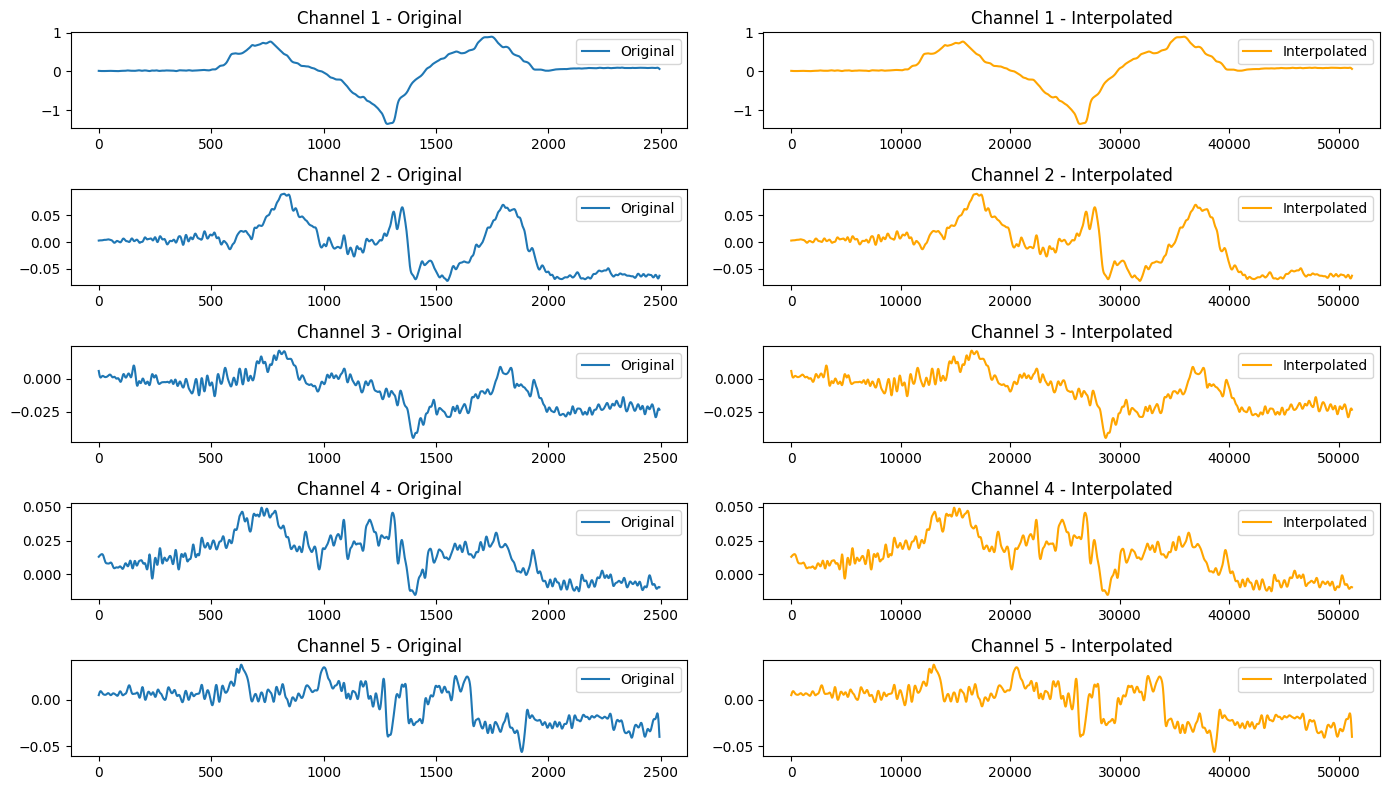

In [9]:
plot_signals(force_signal/0.3, interpolated_force/0.3, signal_names=["Force Channel 1", "Force Channel 2", "Force Channel 3", "Force Channel 4", "Force Channel 5"])